# Thực nghiệm 02 — Thử tham số cho 4 mô hình trên tập A
Mỗi mô hình thay một tham số so với lượt 01. Cả bốn mô hình dùng cùng tập A và cùng 5 fold

## 1. Cấu hình và tham số

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier

cwd = Path.cwd().resolve()
project_dir = next(
    (
        folder
        for folder in (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
        if (folder / "feature_b" / "common.py").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Hãy mở repo sgu-MAYHOC trong VS Code rồi chạy lại.")

sys.path.insert(0, str(project_dir / "feature_b"))
from common import evaluate, load_development

data_path = project_dir / "data" / "processed" / "development.csv"
output_dir = project_dir / "experiments" / "2026-11-13_ThuThamSo_4MoHinh_TapA_Thuong"

N_FOLDS = 5
SEED = 42

configs = {
    "Logistic Regression": (
        LogisticRegression,
        {"C": 1.0, "class_weight": "balanced", "solver": "lbfgs", "max_iter": 3000},
        True,
    ),
    "Random Forest": (
        RandomForestClassifier,
        {
            "n_estimators": 300, "max_depth": None, "min_samples_leaf": 1,
            "class_weight": "balanced", "random_state": SEED, "n_jobs": 1,
        },
        False,
    ),
    "SVM": (
        SVC,
        {"kernel": "rbf", "C": 10, "gamma": 0.001, "class_weight": "balanced"},
        True,
    ),
    "XGBoost": (
        XGBClassifier,
        {
            "n_estimators": 150, "max_depth": 4, "learning_rate": 0.1,
            "objective": "multi:softprob", "num_class": 3,
            "eval_metric": "mlogloss", "tree_method": "hist",
            "random_state": SEED, "n_jobs": 1,
        },
        False,
    ),
}

config_table = pd.DataFrame([
    {
        "Mô hình": name,
        "Tham số thiết lập": ", ".join(f"{key}={value!r}" for key, value in params.items()),
        "Chuẩn hóa cột số": "Có" if scale_numeric else "Không",
    }
    for name, (_, params, scale_numeric) in configs.items()
])
display(config_table)

,Mô hình,Tham số thiết lập,Chuẩn hóa cột số
0,Logistic Regression,"C=1.0, class_weight='balanced', solver='lbfgs'...",Có
1,Random Forest,"n_estimators=300, max_depth=None, min_samples_...",Không
2,SVM,"kernel='rbf', C=10, gamma=0.001, class_weight=...",Có
3,XGBoost,"n_estimators=150, max_depth=4, learning_rate=0...",Không


## 2. Huấn luyện và đánh giá

Mỗi mô hình học trên 4 fold và dự đoán trên fold còn lại. Lặp qua cả 5 fold,
sau đó lấy trung bình Macro-F1 và xếp hạng các mô hình.

In [2]:
X_a, _, y = load_development(data_path)
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows = []
fold_tables = []
parameter_rows = []

for name, (model_class, params, scale_numeric) in configs.items():
    print(f"Đang chạy {name}...")
    model = model_class(**params)
    summary, scores = evaluate(name, model, scale_numeric, "A", X_a, y, folds)
    summary_rows.append(summary)
    fold_tables.append(scores)

    for key, value in model.get_params(deep=False).items():
        parameter_rows.append({
            "Mô hình": name,
            "Tham số": key,
            "Giá trị": repr(value),
        })

results = (
    pd.DataFrame(summary_rows)
    .sort_values("cv_macro_f1", ascending=False)
    .reset_index(drop=True)
)
fold_results = pd.concat(fold_tables, ignore_index=True)
parameters = pd.DataFrame(parameter_rows)

display(results.round(6))
best = results.iloc[0]
print(f"Cao nhất lượt này: {best['model']} ({best['cv_macro_f1']:.6f})")

3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang chạy Logistic Regression...
Đang chạy Random Forest...
Đang chạy SVM...
Đang chạy XGBoost...


,model,data,features,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate
0,Random Forest,A,36,0.722722,0.747581,0.521260,0.884550
1,Logistic Regression,A,36,0.709920,0.739666,0.598425,0.814375
2,XGBoost,A,36,0.709446,0.769569,0.403150,0.926429
3,SVM,A,36,0.702828,0.692172,0.628346,0.814941


Cao nhất lượt này: Random Forest (0.722722)


## 3. Biểu đồ và lưu kết quả

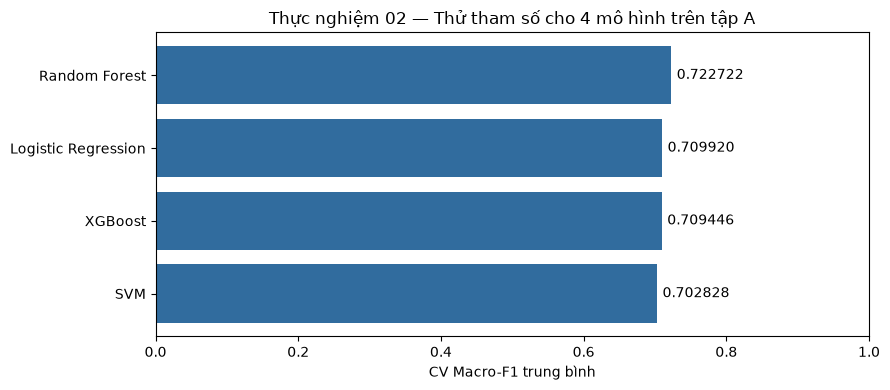

Đã lưu Excel: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-13_ThuThamSo_4MoHinh_TapA_Thuong\ket_qua.xlsx
Đã lưu ảnh: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-13_ThuThamSo_4MoHinh_TapA_Thuong\so_sanh_macro_f1.png


In [3]:
output_dir.mkdir(parents=True, exist_ok=True)
excel_path = output_dir / "ket_qua.xlsx"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Người chạy": "Lê Đỗ Hoà Thương",
    "Tập đặc trưng": "A",
    "Dữ liệu": "data/processed/development.csv",
    "Số mẫu": len(y),
    "Số đặc trưng": X_a.shape[1],
    "Kiểm định chéo": "StratifiedKFold",
    "Số fold": N_FOLDS,
    "Shuffle": True,
    "Random state": SEED,
    "Chỉ số": "CV Macro-F1 trung bình",
}])

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    run_info.to_excel(writer, sheet_name="Cau hinh luot chay", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)
    parameters.to_excel(writer, sheet_name="Tham so day du", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(results["model"], results["cv_macro_f1"], color="#316C9E")
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("CV Macro-F1 trung bình")
ax.set_title("Thực nghiệm 02 — Thử tham số cho 4 mô hình trên tập A")
ax.bar_label(bars, fmt="%.6f", padding=4)
fig.tight_layout()
fig.savefig(image_path, dpi=180)
plt.show()

print(f"Đã lưu Excel: {excel_path}")
print(f"Đã lưu ảnh: {image_path}")

## 4. Nhận xét

Cả bốn mô hình được đánh giá trên cùng 36 đặc trưng của tập A và cùng
5 fold. So với lượt 01, Random Forest tăng CV Macro-F1 từ 0,716244 lên
0,722722 khi tăng số cây từ 200 lên 300. Đây là cấu hình Random Forest
có điểm cao hơn trong hai cấu hình đã thử.

Ba thay đổi còn lại đều làm giảm CV Macro-F1. SVM giảm nhiều nhất,
khoảng 0,012536 khi đổi gamma từ 0,01 xuống 0,001. Trong các cấu hình
đã thử trên tập A, giữ cấu hình lượt 01 cho Logistic Regression,
SVM và XGBoost, đồng thời chọn Random Forest 300 cây để đánh giá tiếp.